# cavity — de Vahl Davis 2D 검증 플롯
로그(`logs/cavity_<Ra>.log`)의 Nu(t) 이력과 `stats/<Ra>/` 중앙선 프로파일을 벤치마크(de Vahl Davis 1983)와 비교한다.
시각화는 show + save (`plot/*.png`).

In [1]:
import re, glob, os
import numpy as np
import matplotlib.pyplot as plt
HERE = os.path.dirname(os.path.abspath("__file__")) if "__file__" in dir() else os.getcwd()
APP = os.path.abspath(os.path.join(HERE, ".."))
BENCH = {  # de Vahl Davis 1983: Nu_avg, u_max(z), w_max(x)
    "1e3": (1.118, 3.649, 0.813, 3.697, 0.178),
    "1e4": (2.243, 16.178, 0.823, 19.617, 0.119),
    "1e5": (4.519, 34.73, 0.855, 68.59, 0.066),
    "1e6": (8.800, 64.63, 0.850, 219.36, 0.0379),
}
CASES = ["1e3", "1e4", "1e5", "1e6"]
SUFFIX = "_mirror"   # 2차 벽(velocity_ghost = mirror) 런; "" 또는 "_value" 로 바꿔 1차 벽 런 비교

def parse_log(path):
    rows = []
    for line in open(path):
        m = re.match(r"\s*(\d+)\s+([\d.]+)\s+([\d.e+-]+)\s+([\d.e+-]+)\s+([\d.e+-]+)\s+([\d.e+-]+)\s+([\d.e+-]+)\s+\(([\d.]+)\)\s+([\d.e+-]+)\s+\(([\d.]+)\)", line)
        if m: rows.append([float(v) for v in m.groups()])
    a = np.array(rows)
    return dict(step=a[:,0], t=a[:,1], dt=a[:,2], div=a[:,3], nu_hot=a[:,4], nu_cold=a[:,5],
                u_max=a[:,6], z_u=a[:,7], w_max=a[:,8], x_w=a[:,9])

def read_sections(path):
    secs, cur = [], []
    for line in open(path):
        if line.startswith("# section"):
            if cur: secs.append(np.array(cur)); cur = []
            continue
        if line.startswith("#") or not line.strip(): continue
        cur.append([float(v) for v in line.split()])
    if cur: secs.append(np.array(cur))
    return secs


## 1. Nu(t) 이력 — 정상상태 도달 확인

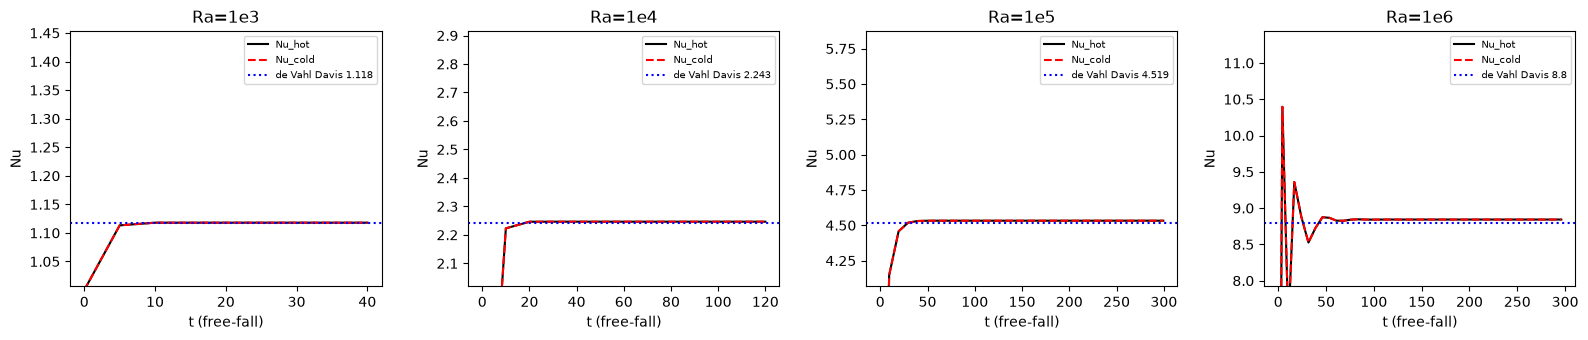

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, ra in zip(axes, CASES):
    logs = glob.glob(f"{APP}/logs/cavity_{ra}{SUFFIX}*.log")
    if not logs: ax.set_title(f"Ra={ra} (no log)"); continue
    L = parse_log(logs[0])
    ax.plot(L["t"], L["nu_hot"], "k-", label="Nu_hot")
    ax.plot(L["t"], L["nu_cold"], "r--", label="Nu_cold")
    ax.axhline(BENCH[ra][0], color="b", ls=":", label=f"de Vahl Davis {BENCH[ra][0]}")
    ax.set_title(f"Ra={ra}"); ax.set_xlabel("t (free-fall)"); ax.set_ylabel("Nu"); ax.legend(fontsize=7)
    ax.set_ylim(0.9*BENCH[ra][0], 1.3*BENCH[ra][0])
plt.tight_layout(); plt.savefig(f"{HERE}/nu_history.png", dpi=130); plt.show()


## 2. 최종값 vs 벤치마크 표

In [3]:
print(f"{'Ra':>5} {'Nu':>8} {'bench':>7} {'err%':>6} | {'u_max':>8} {'bench':>7} {'err%':>6} | {'w_max':>8} {'bench':>7} {'err%':>6}")
for ra in CASES:
    logs = glob.glob(f"{APP}/logs/cavity_{ra}{SUFFIX}*.log")
    if not logs: continue
    L = parse_log(logs[0]); b = BENCH[ra]
    nu, um, wm = L["nu_hot"][-1], abs(L["u_max"][-1]), abs(L["w_max"][-1])
    print(f"{ra:>5} {nu:8.4f} {b[0]:7.3f} {100*(nu/b[0]-1):6.2f} | {um:8.3f} {b[1]:7.3f} {100*(um/b[1]-1):6.2f} | {wm:8.3f} {b[3]:7.3f} {100*(wm/b[3]-1):6.2f}   (t={L['t'][-1]:.0f})")


   Ra       Nu   bench   err% |    u_max   bench   err% |    w_max   bench   err%
  1e3   1.1179   1.118  -0.01 |    3.650   3.649   0.03 |    3.698   3.697   0.03   (t=40)
  1e4   2.2463   2.243   0.15 |   16.183  16.178   0.03 |   19.626  19.617   0.05   (t=120)
  1e5   4.5326   4.519   0.30 |   34.756  34.730   0.07 |   68.668  68.590   0.11   (t=299)
  1e6   8.8425   8.800   0.48 |   64.878  64.630   0.38 |  220.662 219.360   0.59   (t=296)


## 3. 중앙선 프로파일 (최종 통계 파일) — u(z) at x=½, w(x) at z=½, T

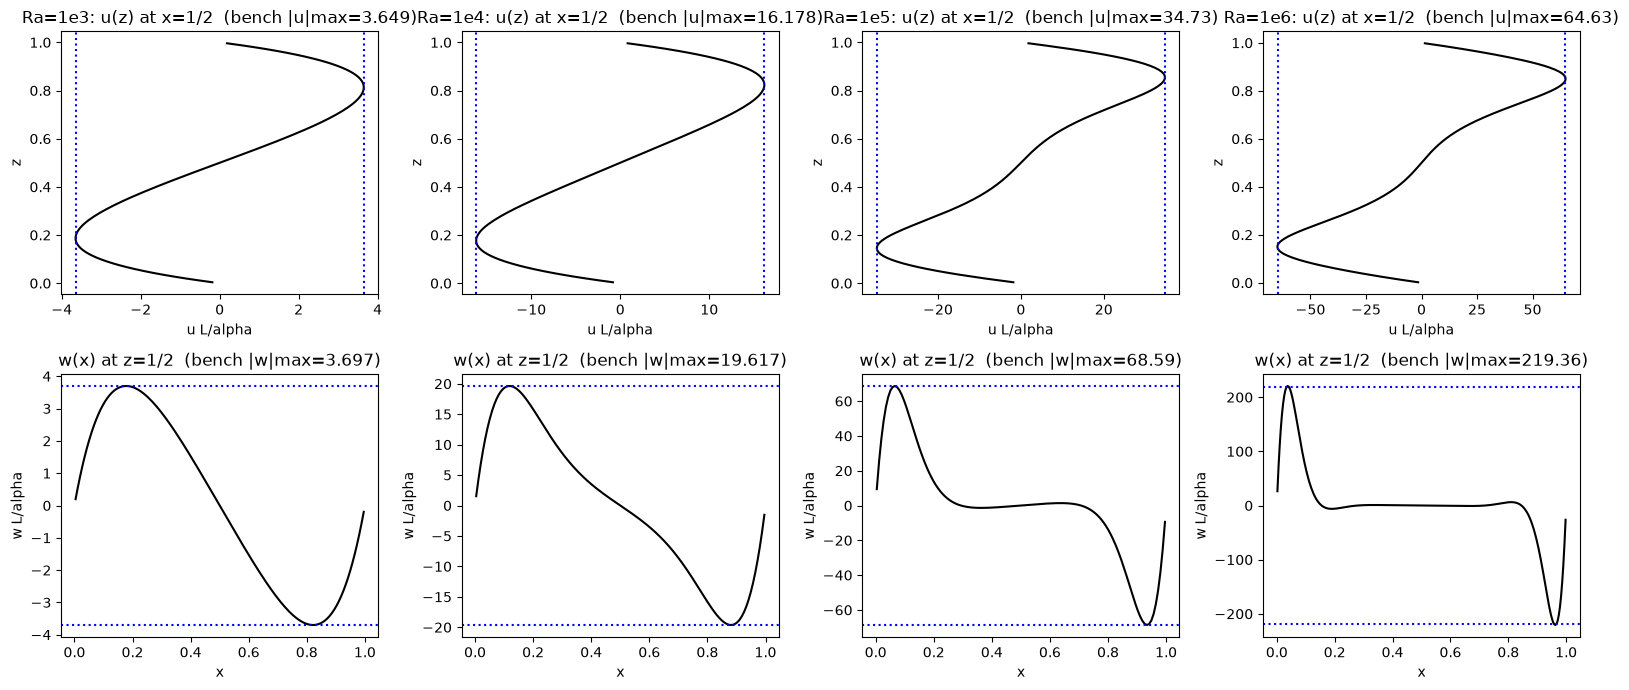

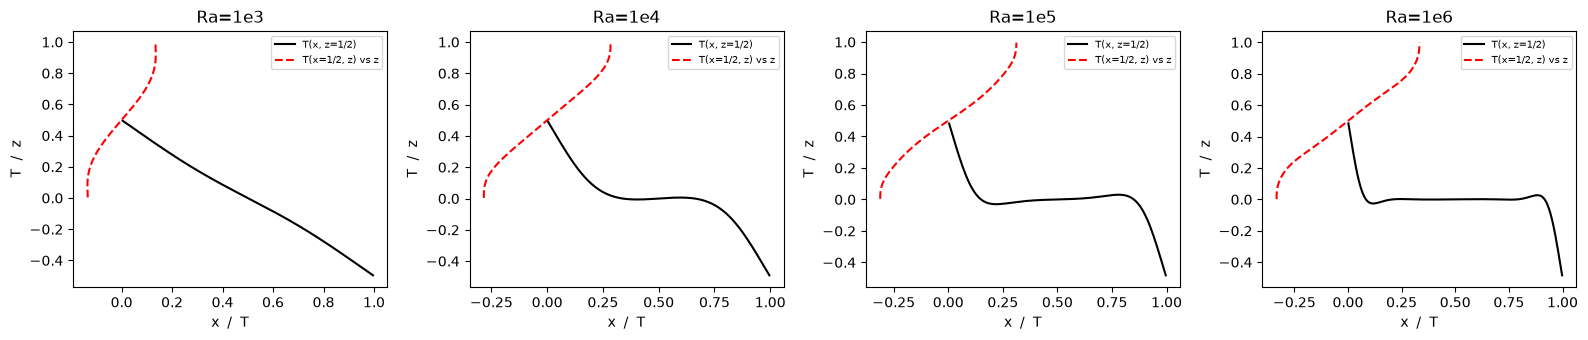

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for c, ra in enumerate(CASES):
    files = sorted(glob.glob(f"{APP}/stats/{ra}{SUFFIX}/cavity_stats_*.dat"))
    if not files: continue
    s1, s2 = read_sections(files[-1])[:2]
    b = BENCH[ra]
    ax = axes[0, c]; ax.plot(s1[:,1], s1[:,0], "k-"); ax.axvline(b[1], color="b", ls=":"); ax.axvline(-b[1], color="b", ls=":")
    ax.set_title(f"Ra={ra}: u(z) at x=1/2  (bench |u|max={b[1]})"); ax.set_xlabel("u L/alpha"); ax.set_ylabel("z")
    ax = axes[1, c]; ax.plot(s2[:,0], s2[:,1], "k-"); ax.axhline(b[3], color="b", ls=":"); ax.axhline(-b[3], color="b", ls=":")
    ax.set_title(f"w(x) at z=1/2  (bench |w|max={b[3]})"); ax.set_xlabel("x"); ax.set_ylabel("w L/alpha")
plt.tight_layout(); plt.savefig(f"{HERE}/midlines.png", dpi=130); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, ra in zip(axes, CASES):
    files = sorted(glob.glob(f"{APP}/stats/{ra}{SUFFIX}/cavity_stats_*.dat"))
    if not files: continue
    s1, s2 = read_sections(files[-1])[:2]
    ax.plot(s2[:,0], s2[:,2], "k-", label="T(x, z=1/2)"); ax.plot(s1[:,2], s1[:,0], "r--", label="T(x=1/2, z) vs z")
    ax.set_title(f"Ra={ra}"); ax.legend(fontsize=7); ax.set_xlabel("x  /  T"); ax.set_ylabel("T  /  z")
plt.tight_layout(); plt.savefig(f"{HERE}/temperature_midlines.png", dpi=130); plt.show()


## 4. Table V 10항목 전수 비교 (pandas)

`plot/benchmark.py` 를 **모듈로** 불러 최종 장 덤프에서 10항목을 계산하고,
논문 Table V(지면 256) 레이아웃 그대로 **우리 값 / 논문 값 / 오차%** 를 나란히 둔다.
err% 칸 색은 논문이 밝힌 자체 불확실도 **Table VII(지면 261: Ra 1e3~1e6 = 0.1/0.2/0.3/1 %)**
기준 — 초록 = 그 안, 노랑 = 2배 이내, 빨강 = 초과. `@x`/`@z` 행은 극값 **위치**라
비율 오차가 뜻이 없어 비워 둔다. 표는 `plot/table_v<SUFFIX>.html` 로도 저장된다.


In [8]:
# ── Table V(논문 지면 256) 전수 비교 — 논문 표 레이아웃 그대로, 우리 값을 바로 옆에 ──
# §2 는 로그에서 Nu_hot·u_max·w_max **3개만** 비교한다. 나머지 7개(|ψ|_mid,
# |ψ|_max, Nu̅, Nu_½, Nu_0, Nu_max, Nu_min)는 **최종 장 덤프**에서만 나오므로
# benchmark.py 를 모듈로 불러 같은 계산을 쓴다 (subprocess 텍스트 출력 대체).
# 색칠 기준 = 논문 자체 불확실도 Table VII(지면 261): Ra 1e3~1e6 → 0.1/0.2/0.3/1 %.
import importlib.util
import pandas as pd

spec = importlib.util.spec_from_file_location("benchmark", f"{HERE}/benchmark.py")
benchmark = importlib.util.module_from_spec(spec)
spec.loader.exec_module(benchmark)

PAPER_UNCERTAINTY = {"1e3": 0.1, "1e4": 0.2, "1e5": 0.3, "1e6": 1.0}   # Table VII
RA_LABEL = {"1e3": "Ra=1e3", "1e4": "Ra=1e4", "1e5": "Ra=1e5", "1e6": "Ra=1e6"}

def mirror_position(value, reference):
    """흐름 방향이 반대로 잡히면 극값 위치는 1−x 대칭 — 가까운 쪽으로 접는다."""
    return value if abs(value - reference) < abs(1 - value - reference) else 1 - value

def table_v_rows(analysis, bench):
    """(행 이름, 우리 값, 논문 값) — Table V 의 행 순서 그대로. '@' 행은 극값 위치."""
    psi_max = bench["psi_max"]        # 1e3·1e4 는 중점과 같아 논문이 '—' 로 둔다
    return [
        ("|psi|_mid",      analysis["psi_mid"],       bench["psi_mid"]),
        ("|psi|_max",      analysis["psi_max"][0],    psi_max[0] if psi_max else np.nan),
        ("|psi|_max @x",   analysis["psi_max"][1],    psi_max[1] if psi_max else np.nan),
        ("|psi|_max @z",   analysis["psi_max"][2],    psi_max[2] if psi_max else np.nan),
        ("u_max",          analysis["u_max"][0],      bench["u_max"][0]),
        ("u_max @z",       mirror_position(analysis["u_max"][1], bench["u_max"][1]),
                                                      bench["u_max"][1]),
        ("w_max",          analysis["w_max"][0],      bench["w_max"][0]),
        ("w_max @x",       mirror_position(analysis["w_max"][1], bench["w_max"][1]),
                                                      bench["w_max"][1]),
        ("Nu_bar",         analysis["nu_bar"],        bench["nu_bar"]),
        ("Nu_1/2",         analysis["nu_half"],       bench["nu_half"]),
        ("Nu_0",           analysis["nu_0"],          bench["nu_0"]),
        ("Nu_max",         analysis["nu_max"][0],     bench["nu_max"][0]),
        ("Nu_max @z",      analysis["nu_max"][1],     bench["nu_max"][1]),
        ("Nu_min",         analysis["nu_min"][0],     bench["nu_min"][0]),
        ("Nu_min @z",      analysis["nu_min"][1],     bench["nu_min"][1]),
    ]

columns, row_names, present = {}, None, []
for ra in CASES:
    dumps = sorted(glob.glob(f"{APP}/stats/{ra}{SUFFIX}/cavity_field_*.dat"))
    if not dumps:
        print(f"[{ra}] 장 덤프 없음 — 표에서 빠진다 (stats/{ra}{SUFFIX}/cavity_field_*.dat)")
        continue
    dump = benchmark.read_dump(dumps[-1])
    analysis = benchmark.analyze(dump)
    rows = table_v_rows(analysis, benchmark.BENCH[dump["ra"]])
    row_names = [name for name, _, _ in rows]
    label = RA_LABEL[ra]
    columns[(label, "ours")] = [ours for _, ours, _ in rows]
    columns[(label, "bench")] = [ref for _, _, ref in rows]
    # 위치('@') 행은 비율 오차가 뜻이 없다 — 비워 둔다
    columns[(label, "err%")] = [
        np.nan if ("@" in name or not ref or np.isnan(ref)) else 100 * (ours / ref - 1)
        for name, ours, ref in rows]
    present.append(ra)
    print(f"[{ra}] {os.path.relpath(dumps[-1], APP)}  {dump['nx']}x{dump['nz']}  "
          f"t={dump['t']:.0f}  (psi 상단벽 잔차 {analysis['psi_top_residual']:.1e}, "
          f"Nu_min 벽 외삽 z=1: {analysis['nu_wall_at_z1']:.4f})")

table = pd.DataFrame(columns, index=row_names)
table.columns = pd.MultiIndex.from_tuples(table.columns)
label_to_ra = {RA_LABEL[ra]: ra for ra in present}

def shade_error(column):
    """err% 칸만 칠한다 — 논문 자체 불확실도(Table VII) 이내 / 2배 이내 / 초과."""
    if column.name[1] != "err%":
        return [""] * len(column)
    tolerance = PAPER_UNCERTAINTY[label_to_ra[column.name[0]]]
    styles = []
    for value in column:
        if pd.isna(value):
            styles.append("")
        elif abs(value) <= tolerance:
            styles.append("background-color:#d6ecd6")       # 논문 불확실도 안
        elif abs(value) <= 2 * tolerance:
            styles.append("background-color:#fdf1cd")       # 2배 이내
        else:
            styles.append("background-color:#f8d7da")       # 초과
    return styles

styled = (table.style
          .format({c: ("{:+.2f}" if c[1] == "err%" else "{:.5g}") for c in table.columns},
                  na_rep="—")
          # .apply(shade_error, axis=0)
          .set_caption(f"de Vahl Davis (1983) Table V 전수 비교 — velocity_ghost{SUFFIX}"
                       "　|　색: 논문 Table VII 불확실도(1e3~1e6 = 0.1/0.2/0.3/1%) "
                       "이내(초록) · 2배 이내(노랑) · 초과(빨강)")
          .set_table_styles([{"selector": "caption",
                              "props": "caption-side:top; font-size:0.95em; padding-bottom:6px;"},
                             {"selector": "th", "props": "text-align:center;"}]))
try:
    display(styled)                       # 노트북: 색칠된 HTML 표
except NameError:                         # 스크립트/배치 실행
    print("(노트북이 아니라 HTML 표는 생략 — 아래 텍스트 표를 본다)")
with open(f"{HERE}/table_v{SUFFIX}.html", "w") as f:
    f.write(styled.to_html())

# 노트북 밖(스크립트)에서도 읽히도록 같은 내용을 텍스트로 한 번 더
print("\n" + table.to_string(float_format=lambda v: f"{v:9.5g}", na_rep="—"))
worst = {RA_LABEL[ra]: table[(RA_LABEL[ra], "err%")].abs().max() for ra in present}
print("\nRa별 최대 |오차| :  " + "  ".join(f"{k} {v:.2f}%" for k, v in worst.items())
      + "   (논문 자체 불확실도 " + "/".join(f"{PAPER_UNCERTAINTY[ra]:g}" for ra in present) + " %)")

[1e3] stats/1e3_mirror/cavity_field_00008000.dat  128x128  t=40  (psi 상단벽 잔차 1.3e-13, Nu_min 벽 외삽 z=1: 0.6911)
[1e4] stats/1e4_mirror/cavity_field_00012000.dat  128x128  t=120  (psi 상단벽 잔차 4.4e-13, Nu_min 벽 외삽 z=1: 0.5849)
[1e5] stats/1e5_mirror/cavity_field_00030058.dat  128x128  t=300  (psi 상단벽 잔차 1.0e-12, Nu_min 벽 외삽 z=1: 0.7275)
[1e6] stats/1e6_mirror/cavity_field_00041546.dat  256x256  t=300  (psi 상단벽 잔차 1.4e-12, Nu_min 벽 외삽 z=1: 0.9788)



                Ra=1e3                         Ra=1e4                        Ra=1e5                        Ra=1e6                    
                  ours     bench       err%      ours     bench      err%      ours     bench      err%      ours     bench      err%
|psi|_mid       1.1752     1.174    0.10263    5.0751     5.071   0.08141    9.1252     9.111   0.15532    16.404     16.32   0.51335
|psi|_max       1.1752         —          —    5.0751         —         —    9.6258     9.612   0.14407    16.827     16.75   0.46193
|psi|_max @x       0.5         —          —       0.5         —         —   0.28444     0.285         —   0.15034     0.151         —
|psi|_max @z       0.5         —          —       0.5         —         —   0.60123     0.601         —   0.54761     0.547         —
u_max           3.6502     3.649   0.032794    16.183    16.178  0.033499    34.757     34.73  0.078102    64.878     64.63   0.38386
u_max @z       0.81327     0.813          —   0.82326     0.8